# 03 – Análise descritiva

**Objetivo:** descrever o dataset limpo e explorar, de forma descritiva, as hipóteses do projeto:
estatísticas resumo, comparações entre grupos, visualizações e matriz de correlação.

**Escopo:** Não serão aplicados testes de hipótese. As hipóteses são
tratadas como exploratórias, e as conclusões descrevem este conjunto de dados, sem generalização.

In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from src.funcoes import (
    carregar_dados, contar_artistas, 
    configurar_estilo, plotar_barras_horizontais,
    plotar_histograma, analisar_descritiva,
    resumir_por_grupo, plotar_boxplot, rotular_eixo_log_milhoes,
    plotar_heatmap, classificar_correlacao, plotar_dispersao,
    adicionar_linha_medianas, COR_PRINCIPAL, COR_DESTAQUE, 
    plotar_histogramas_grade,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)


In [2]:
df = carregar_dados("../data/spotify_2023_limpo.csv")

df["data_lancamento"] = pd.to_datetime(df["data_lancamento"])
df = df.set_index("id_original")

df.info()

configurar_estilo()

Dados carregados: 949 linhas e 22 colunas.
<class 'pandas.DataFrame'>
Index: 949 entries, 0 to 952
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   track_name            949 non-null    str           
 1   artist_name           949 non-null    str           
 2   artist_count          949 non-null    int64         
 3   released_year         949 non-null    int64         
 4   released_month        949 non-null    int64         
 5   released_day          949 non-null    int64         
 6   streams               947 non-null    float64       
 7   in_spotify_playlists  949 non-null    int64         
 8   in_spotify_charts     949 non-null    int64         
 9   bpm                   949 non-null    int64         
 10  key                   949 non-null    str           
 11  mode                  949 non-null    str           
 12  danceability          949 non-null    int64        

In [3]:
caracteristicas_audio = ["bpm", "danceability", "valence", "energy", "acousticness",
                         "instrumentalness", "liveness", "speechiness"]

rotulos_pt = {
    "bpm": "BPM", "danceability": "Dançabilidade", "valence": "Valência",
    "energy": "Energia", "acousticness": "Acústica", "instrumentalness": "Instrumental",
    "liveness": "Ao vivo", "speechiness": "Fala",
    "streams": "Streams", "in_spotify_playlists": "Playlists", "in_spotify_charts": "Charts",
}

## 1. Descrição do dataset

### 1.1 Artistas mais frequentes
Músicas com colaboração têm vários artistas na mesma célula (`"A, B"`). Para contar cada artista,
separa-se os nomes. Antes, valida-se a separação: o número de nomes obtido deve coincidir com
a coluna `artist_count`.

In [4]:
n_nomes = df["artist_name"].str.split(", ").str.len()
divergentes = df[n_nomes != df["artist_count"]]

print(f"Músicas em que o número de nomes difere de artist_count: {len(divergentes)}")
divergentes[["track_name", "artist_name", "artist_count"]].assign(nomes_separados=n_nomes)

Músicas em que o número de nomes difere de artist_count: 1


,track_name,artist_name,artist_count,nomes_separados
id_original,,,,
667,"Cay�� La Noche (feat. Cruz Cafun��, Abhir Hath...","Quevedo, La Pantera, Juseph, Cruz Cafun��, B��...",7,6


In [5]:
contagem_artistas = contar_artistas(df, "artist_name")

print(f"Artistas distintos: {len(contagem_artistas)}")
contagem_artistas.head(15)

Artistas distintos: 698


artist_name
Bad Bunny         40
Taylor Swift      38
The Weeknd        36
SZA               23
Kendrick Lamar    23
Feid              21
Drake             19
Harry Styles      17
Peso Pluma        16
21 Savage         14
Metro Boomin      14
Ed Sheeran        14
Morgan Wallen     13
BTS               13
Quevedo           12
Name: count, dtype: int64

In [6]:
top_artistas = contagem_artistas.head(15).index
todos_os_nomes = contagem_artistas.index

for artista in top_artistas:
    variantes = [nome for nome in todos_os_nomes
                 if nome != artista and artista.startswith(nome)]
    if variantes:
        contagens = {nome: contagem_artistas[nome] for nome in variantes}
        print(f"{artista}: {contagens}")

Bad Bunny: {'Bad B': np.int64(1)}
Peso Pluma: {'Peso P': np.int64(2)}
Metro Boomin: {'M': np.int64(1)}
Morgan Wallen: {'M': np.int64(1)}


In [7]:
tem_nome_vazio = df["artist_name"].str.split(", ").apply(
    lambda nomes: any(nome.strip() == "" for nome in nomes)
)
df.loc[tem_nome_vazio, ["track_name", "artist_name", "artist_count"]]

,track_name,artist_name,artist_count
id_original,,,
742,Vampiro,"Matu��, Wiu,",3


In [8]:
tem_m = df["artist_name"].str.split(", ").apply(lambda nomes: "M" in nomes)
df.loc[tem_m, ["track_name", "artist_name", "released_year"]]

,track_name,artist_name,released_year
id_original,,,
488,Tubar��o Te,"Dj LK da Esc��cia, Tchakabum, mc jhenny, M",2022


**Nomes truncados:** buscando nomes que são o início de artistas do top 15, encontra-se
"Bad B" (Bad Bunny, 1 ocorrência) e "Peso P" (Peso Pluma, 2), que são corrigidos antes da contagem.
"M" não é corrigido, pois não da para saber de qual artista se trata.
Duas músicas perderam um artista inteiro no truncamento ("Cayó La Noche" e
"Vampiro"); o nome vazio gerado em "Vampiro" é descartado. Limitação: pequena subcontagem.

In [9]:
correcoes_artistas = {
    "Bad B": "Bad Bunny",
    "Peso P": "Peso Pluma",
}

contagem_artistas = contar_artistas(df, "artist_name", correcoes=correcoes_artistas)

print(f"Artistas distintos: {len(contagem_artistas)}")
assert contagem_artistas["Bad Bunny"] == 41, "Bad Bunny deveria ter 41"
assert contagem_artistas["Peso Pluma"] == 18, "Peso Pluma deveria ter 18"
assert "" not in contagem_artistas.index, "Não deveria haver nome vazio"

contagem_artistas.head(15)

Artistas distintos: 696


artist_name
Bad Bunny         41
Taylor Swift      38
The Weeknd        36
SZA               23
Kendrick Lamar    23
Feid              21
Drake             19
Peso Pluma        18
Harry Styles      17
21 Savage         14
Metro Boomin      14
Ed Sheeran        14
Morgan Wallen     13
BTS               13
Quevedo           12
Name: count, dtype: int64

In [10]:
# Testando se a função 'contar_artistas' está funcionando corretamente:

teste = pd.DataFrame({"art": ["A, B", "A", "B, Bx, ", "C"]})
resultado = contar_artistas(teste, "art", correcoes={"Bx": "B"})
print(resultado)

assert resultado["A"] == 2, "A aparece 2 vezes"
assert resultado["B"] == 3, "B aparece 1 vez + 'Bx' corrigido + 1 na linha 3"
assert "" not in resultado.index, "O nome vazio deveria ser descartado"
assert len(resultado) == 3, "Deveriam sobrar só A, B e C"
print("Testes OK")

art
B    3
A    2
C    1
Name: count, dtype: int64
Testes OK


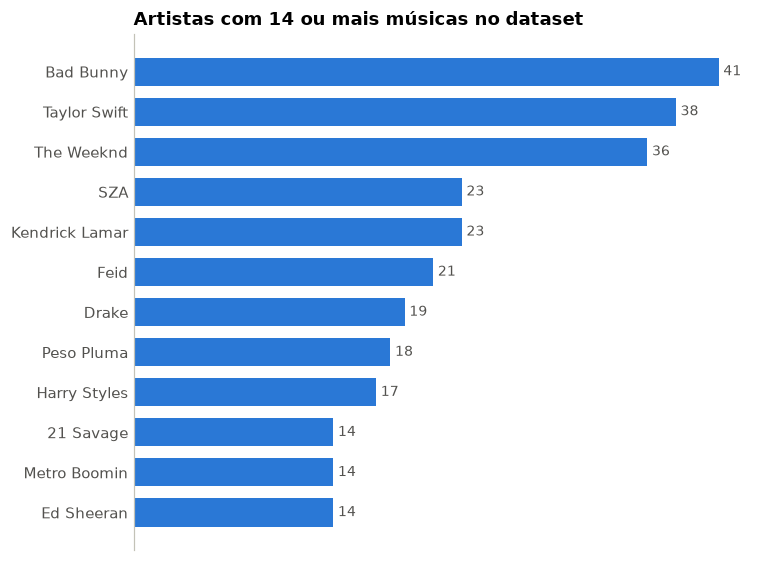

In [11]:
top_artistas = contagem_artistas[contagem_artistas >= 14]

fig, ax = plotar_barras_horizontais(
    top_artistas,
    titulo="Artistas com 14 ou mais músicas no dataset",
    caminho="../figures/artistas_mais_frequentes.png",
)

**Leitura:** o dataset é concentrado em poucos artistas. Bad Bunny (41), Taylor Swift (38) e
The Weeknd (36) somam 115 músicas, cerca de 12% do total. Isso reflete o efeito de lançamentos de
álbuns de sucesso, que colocam várias faixas entre as mais ouvidas ao mesmo tempo.

### 1.2 Distribuição dos anos de lançamento
O dataset reúne as músicas mais ouvidas em 2023, mas inclui lançamentos de várias épocas.
Vemos primeiro a distribuição por década (panorama) e depois ano a ano a partir de 2010 (detalhe).

[Text(0, 0, '2'),
 Text(0, 0, '9'),
 Text(0, 0, '4'),
 Text(0, 0, '7'),
 Text(0, 0, '12'),
 Text(0, 0, '14'),
 Text(0, 0, '20'),
 Text(0, 0, '151'),
 Text(0, 0, '730')]

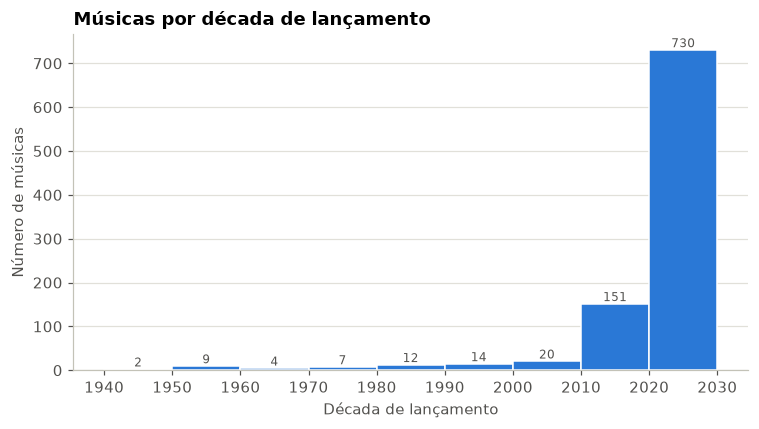

In [12]:
decadas = list(range(1940, 2031, 10))

fig, ax = plotar_histograma(
    df["released_year"],
    bins=decadas,
    titulo="Músicas por década de lançamento",
    rotulo_x="Década de lançamento",
    caminho="../figures/anos_por_decada.png",
)
ax.set_xticks(decadas)
ax.bar_label(ax.containers[0], fontsize=8, color="#52514e")

[Text(0, 0, '7'),
 Text(0, 0, '10'),
 Text(0, 0, '10'),
 Text(0, 0, '13'),
 Text(0, 0, '13'),
 Text(0, 0, '11'),
 Text(0, 0, '18'),
 Text(0, 0, '23'),
 Text(0, 0, '10'),
 Text(0, 0, '36'),
 Text(0, 0, '37'),
 Text(0, 0, '118'),
 Text(0, 0, '400'),
 Text(0, 0, '175')]

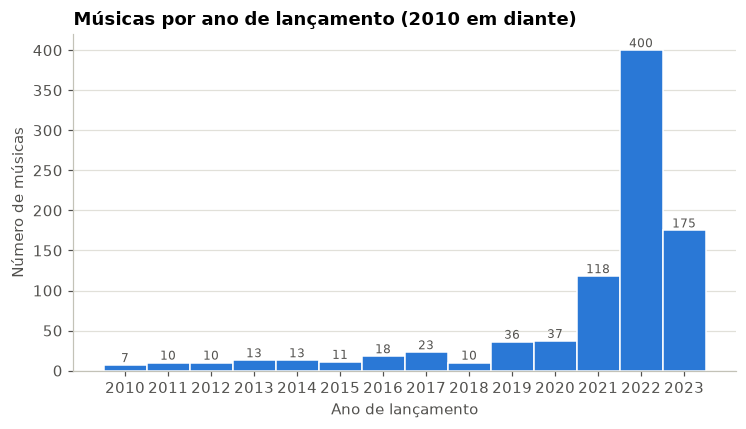

In [13]:
limites_recentes = np.arange(2009.5, 2024.5, 1)
anos_recentes = list(range(2010, 2024))

fig, ax = plotar_histograma(
    df.loc[df["released_year"] >= 2010, "released_year"],
    bins=limites_recentes,
    titulo="Músicas por ano de lançamento (2010 em diante)",
    rotulo_x="Ano de lançamento",
    caminho="../figures/anos_desde_2010.png",
)
ax.set_xticks(anos_recentes)
ax.bar_label(ax.containers[0], fontsize=8, color="#52514e")

**Leitura:** a distribuição dos anos é fortemente assimétrica à esquerda. A década de 2020 concentra
730 músicas (77%), mesmo cobrindo apenas 2020–2023; apenas 68 (7%) são anteriores a 2010
(clássicos, muitos natalinos). Entre as recentes, 2022 é o ano com mais músicas (400). 2023 tem
bem menos (175), apesar de o dataset ser das mais ouvidas em 2023: o ano estava incompleto na
coleta, e músicas recentes tiveram pouco tempo para acumular streams (viés de tempo de exposição).
Obs.: o gráfico conta músicas por período, não streams por música.

### 1.3 Perfil sonoro das músicas mais ouvidas
Distribuição das características musicais no dataset. **Detalhe importante:** Como o dataset contém apenas músicas de
sucesso e não há grupo de comparação, os resultados descrevem o perfil das músicas mais ouvidas,
e não o que distingue músicas de sucesso de músicas em geral.

,músicas,%
key,,
C,94,9.90
C#,119,12.50
D,81,8.50
D#,33,3.50
E,62,6.50
F,89,9.40
F#,73,7.70
G,96,10.10
G#,91,9.60


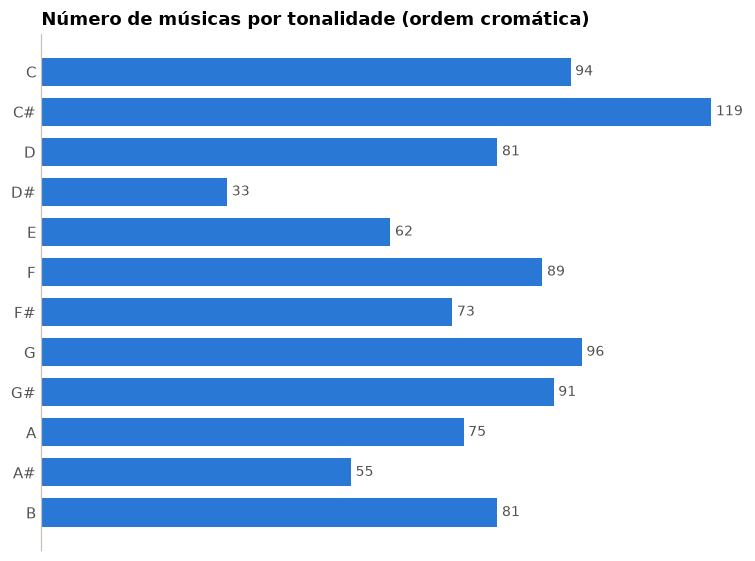

In [14]:
notas = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

contagem_notas = df["key"].value_counts().reindex(notas)

display(pd.DataFrame({
    "músicas": contagem_notas,
    "%": (contagem_notas / len(df) * 100).round(1),
}))

fig, ax = plotar_barras_horizontais(
    contagem_notas,
    titulo="Número de músicas por tonalidade (ordem cromática)",
    caminho="../figures/tonalidades.png",
)

In [15]:
# Análise dos modos

modo_pt = df["mode"].map({"Major": "Maior", "Minor": "Menor"})

pd.DataFrame({
    "músicas": modo_pt.value_counts(),
    "%": (modo_pt.value_counts(normalize=True) * 100).round(1),
})

,músicas,%
mode,,
Maior,548,57.70
Menor,401,42.30


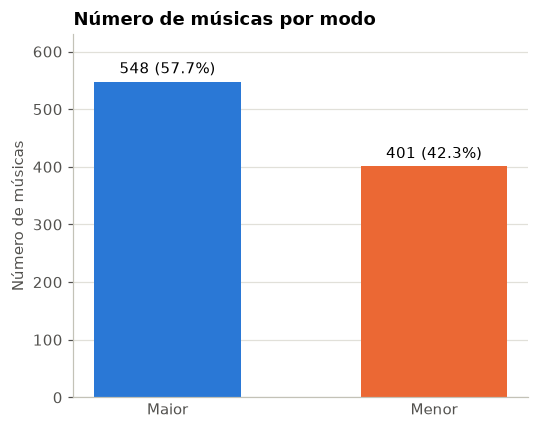

In [16]:
# Gráfico: 

contagem_modo = modo_pt.value_counts().reindex(["Maior", "Menor"])
proporcao_modo = contagem_modo / contagem_modo.sum() * 100

fig, ax = plt.subplots(figsize=(5, 4))

barras = ax.bar(contagem_modo.index, contagem_modo.values,
                color=[COR_PRINCIPAL, COR_DESTAQUE], width=0.55)

rotulos = [f"{n} ({p:.1f}%)" for n, p in zip(contagem_modo.values, proporcao_modo.values)]
ax.bar_label(barras, labels=rotulos, padding=3, fontsize=10)

ax.set_title("Número de músicas por modo", loc="left")
ax.set_ylabel("Número de músicas")
ax.set_ylim(0, contagem_modo.max() * 1.15)
ax.grid(axis="y")
ax.set_axisbelow(True)
ax.tick_params(axis="x", length=0)

fig.tight_layout()
fig.savefig("../figures/modos.png", bbox_inches="tight")

In [17]:
analisar_descritiva(df, caracteristicas_audio)

,n,média,mediana,desvio padrão,mínimo,Q1,Q3,máximo,assimetria
bpm,949,122.46,120.00,28.04,65,99.00,140.00,206,0.42
danceability,949,66.96,69.00,14.65,23,57.00,78.00,96,-0.43
valence,949,51.42,51.00,23.51,4,32.00,70.00,97,0.01
energy,949,64.26,66.00,16.58,9,53.00,77.00,97,-0.44
acousticness,949,27.14,18.00,26.02,0,6.00,43.00,97,0.95
instrumentalness,949,1.57,0.00,8.41,0,0.00,0.00,91,7.16
liveness,949,18.17,12.00,13.70,3,10.00,23.00,97,2.12
speechiness,949,10.15,6.00,9.93,2,4.00,11.00,64,1.93


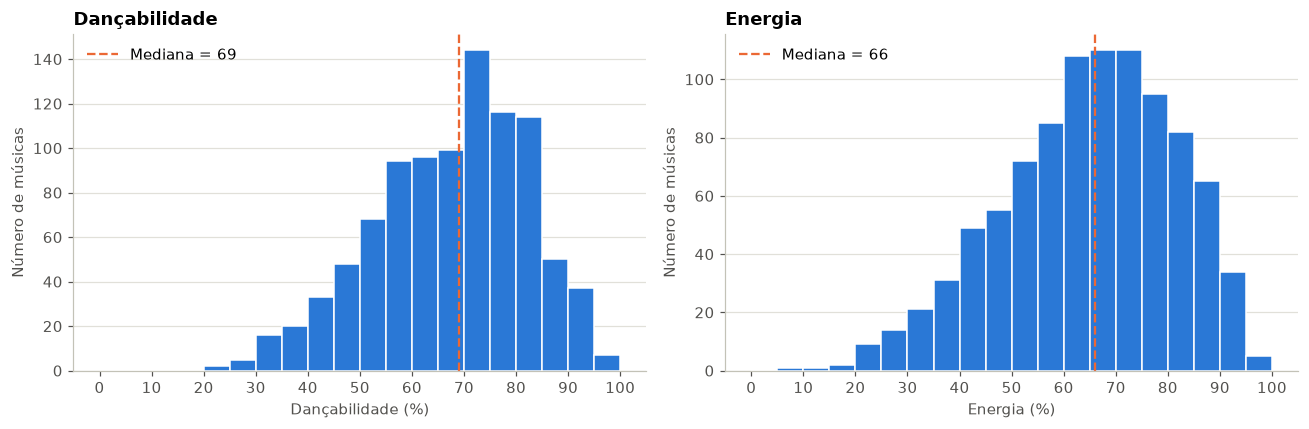

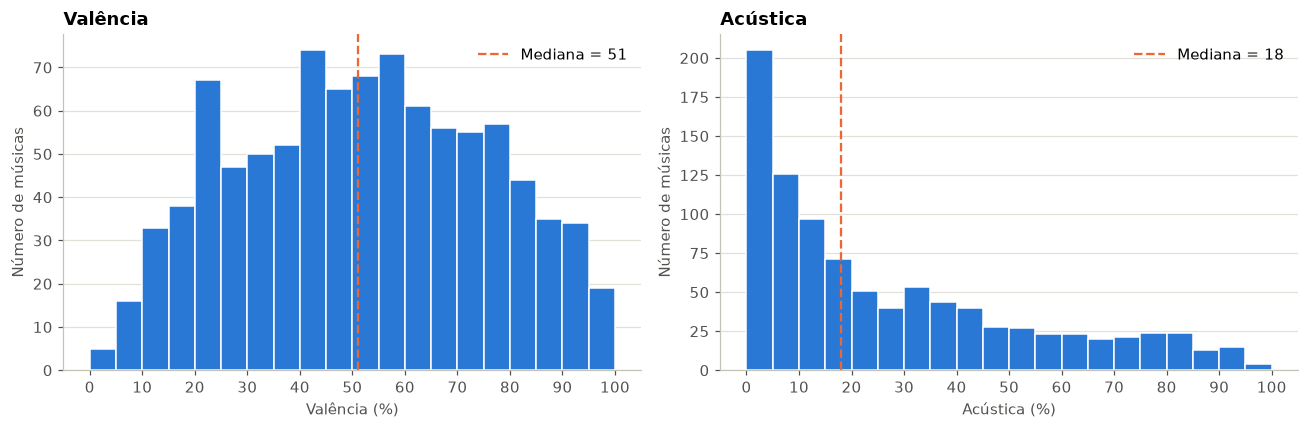

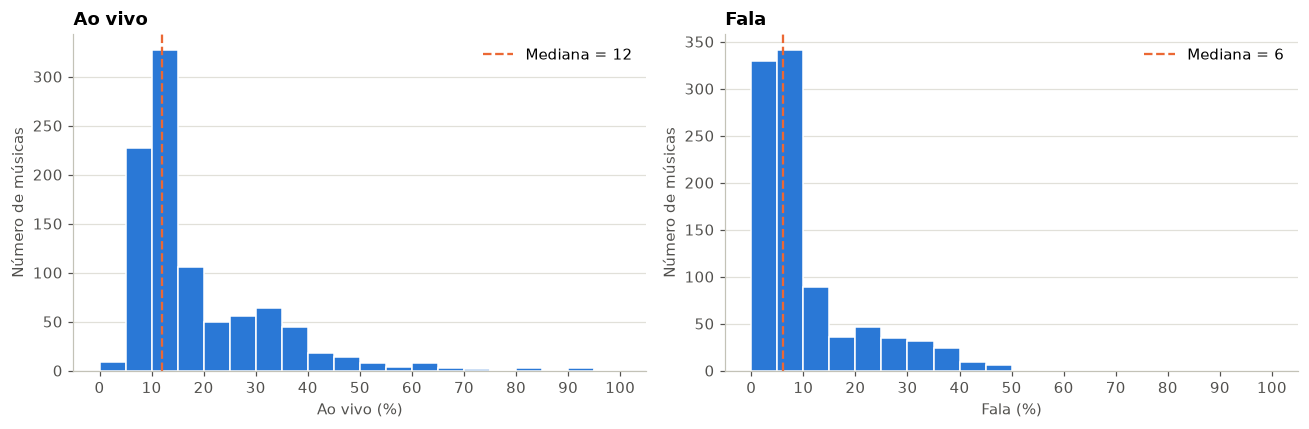

In [19]:
pares = [
    ("danceability", "energy"),
    ("valence", "acousticness"),
    ("liveness", "speechiness"),
]

for coluna_1, coluna_2 in pares:
    fig, eixos = plotar_histogramas_grade(
        df, [coluna_1, coluna_2], rotulos_pt,
        bins=np.arange(0, 101, 5),
        marcas_x=range(0, 101, 10),
        caminho=f"../figures/histogramas_{coluna_1}_{coluna_2}.png",
    )

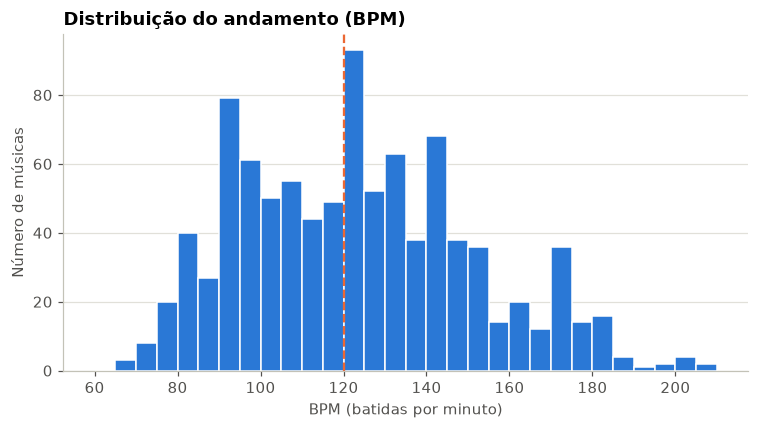

In [ ]:
fig, ax = plotar_histograma(
    df["bpm"],
    bins=np.arange(60, 215, 5),
    titulo="Distribuição do andamento (BPM)",
    rotulo_x="BPM (batidas por minuto)",
    caminho="../figures/bpm_histograma.png",
)
ax.axvline(df["bpm"].median(), color=COR_DESTAQUE, linewidth=1.5, linestyle="--")
fig.savefig("../figures/bpm_histograma.png", bbox_inches="tight")

In [20]:
pct_zero = (df["instrumentalness"] == 0).mean()
print(f"Músicas com instrumentalidade igual a zero: {pct_zero:.1%}")

Músicas com instrumentalidade igual a zero: 90.9%


**Leitura:** o perfil sonoro das músicas mais ouvidas é concentrado em algumas características.
**Dançabilidade** (mediana 69; metade entre 57 e 78) e **energia** (mediana 66; entre 53 e 77) se
concentram em valores altos, com leve assimetria à esquerda. **Acústica** (mediana 18), **ao vivo**
(12) e **fala** (6) se acumulam em valores baixos, com assimetria à direita: a maioria das músicas é
produzida em estúdio, pouco acústica e cantada. A **instrumentalidade** é zero em 90.9% das músicas,
praticamente todas têm vocal. O **BPM** tem mediana de 120 e se distribui entre ~65 e ~210, com
concentrações em torno de 90–95, 120 e 140.

A exceção é a **valência**, que se distribui de forma quase simétrica por toda a escala
(mediana 51; metade entre 32 e 70; assimetria ≈ 0): músicas mais "tristes" e mais "alegres" estão
igualmente presentes entre as mais ouvidas. 

## 2. Distribuição das variáveis de sucesso
As três medidas de sucesso: `streams`, `in_spotify_playlists` e `in_spotify_charts`.

In [ ]:
variaveis_sucesso = ["streams", "in_spotify_playlists", "in_spotify_charts"]
analisar_descritiva(df, variaveis_sucesso)

,n,média,mediana,desvio padrão,mínimo,Q1,Q3,máximo,assimetria
streams,947,"514,879,661.09","290,228,626.00","567,850,736.57","1,365,184.00","141,908,137.00","673,228,688.00","3,703,895,074.00",2.00
in_spotify_playlists,949,"5,214.33","2,224.00","7,911.05",31.00,875.00,"5,669.00","52,898.00",2.92
in_spotify_charts,949,12.06,3.00,19.60,0.00,0.00,16.00,147.00,2.57


### 2.1 Streams

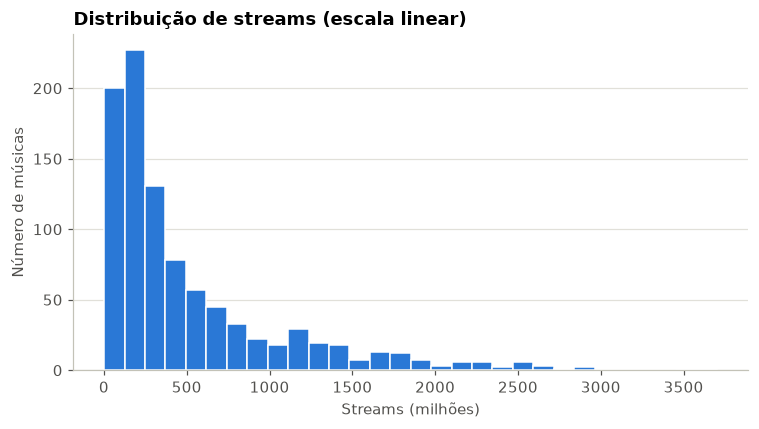

In [ ]:
streams_mi = df["streams"] / 1_000_000

fig, ax = plotar_histograma(
    streams_mi,
    bins=30,
    titulo="Distribuição de streams (escala linear)",
    rotulo_x="Streams (milhões)",
)

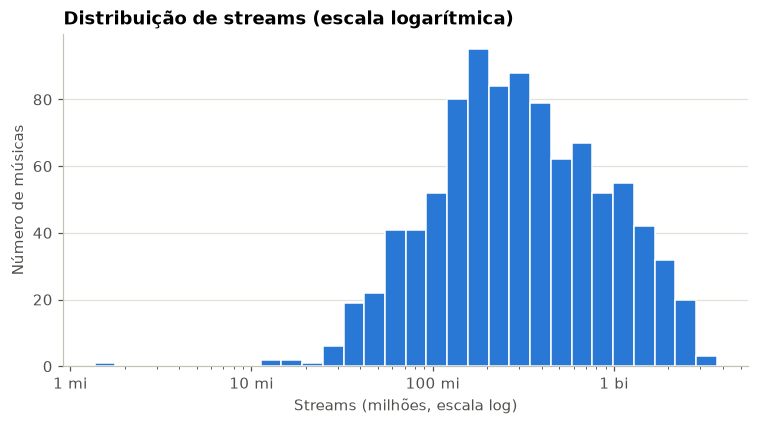

In [ ]:
fig, ax = plotar_histograma(
    streams_mi,
    bins=30,
    titulo="Distribuição de streams (escala logarítmica)",
    rotulo_x="Streams (milhões, escala log)",
    escala_log=True,
    caminho="../figures/streams_histograma_log.png",
)

marcas = [1, 10, 100, 1000]
ax.set_xticks(marcas)
ax.set_xticklabels(["1 mi", "10 mi", "100 mi", "1 bi"])
fig.savefig("../figures/streams_histograma_log.png", bbox_inches="tight")

**Leitura:** as três medidas de sucesso têm assimetria forte à direita (coeficiente entre 2,0 e 2,9):
a média é bem maior que a mediana e, em `streams` e playlists, o desvio padrão supera a média.
Por isso, usa-se a **mediana** e os **quartis** como medidas de centro e dispersão.
Metade das músicas tem entre 142 mi (Q1) e 673 mi (Q3) de streams, com mediana de 290 mi.
Em escala linear, os valores baixos se concentram nas primeiras classes; em escala logarítmica,
a distribuição de `streams` fica aproximadamente simétrica, com pico
entre 150 e 400 milhões. Destacam-se um valor isolado em torno de 1 mi e um pequeno grupo entre
10 e 30 mi (lançamentos recentes, com pouco tempo de exposição).

### 2.2 Presença em playlists

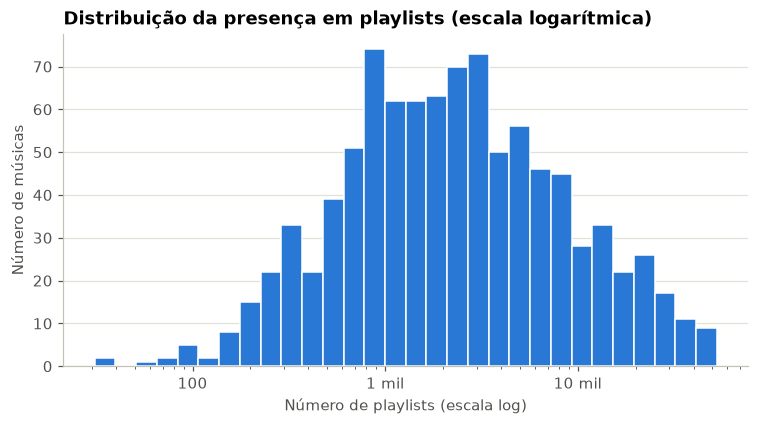

In [ ]:
fig, ax = plotar_histograma(
    df["in_spotify_playlists"],
    bins=30,
    titulo="Distribuição da presença em playlists (escala logarítmica)",
    rotulo_x="Número de playlists (escala log)",
    escala_log=True,
)
marcas = [100, 1_000, 10_000]
ax.set_xticks(marcas)
ax.set_xticklabels(["100", "1 mil", "10 mil"])
fig.savefig("../figures/playlists_histograma_log.png", bbox_inches="tight")

### 2.3 Presença nos charts
A descrição do Kaggle ("presence and rank") é ambígua: o valor pode ser uma posição no ranking
(menor = melhor) ou uma medida de presença (maior = melhor). Investiga-se pelos próprios dados
antes de usar a variável.

In [ ]:
# Conferindo a proporção de zeros na in_spotify_charts

zeros = (df["in_spotify_charts"] == 0).sum()
print(f"Músicas fora dos charts: {zeros} de {len(df)} ({zeros / len(df):.1%})")

Músicas fora dos charts: 402 de 949 (42.4%)


In [ ]:
# Testando os valores

colunas_charts = ["track_name", "artist_name", "released_year", "released_month",
                  "streams", "in_spotify_playlists", "in_spotify_charts"]
df.nlargest(10, "in_spotify_charts")[colunas_charts]

,track_name,artist_name,released_year,released_month,streams,in_spotify_playlists,in_spotify_charts
id_original,,,,,,,
0,Seven (feat. Latto) (Explicit Ver.),"Latto, Jung Kook",2023,7,"141,381,703.00",553,147
14,As It Was,Harry Styles,2022,3,"2,513,188,493.00",23575,130
12,Flowers,Miley Cyrus,2023,1,"1,316,855,716.00",12211,115
2,vampire,Olivia Rodrigo,2023,6,"140,003,974.00",1397,113
22,I Wanna Be Yours,Arctic Monkeys,2013,1,"1,297,026,226.00",12859,110
17,What Was I Made For? [From The Motion Picture ...,Billie Eilish,2023,7,"30,546,883.00",873,104
29,Dance The Night (From Barbie The Album),Dua Lipa,2023,5,"127,408,954.00",2988,101
3,Cruel Summer,Taylor Swift,2019,8,"800,840,817.00",7858,100
13,Daylight,David Kushner,2023,4,"387,570,742.00",3528,98


In [ ]:
# Procurando uma correlação com outras medidas de sucesso:

nos_charts = df[df["in_spotify_charts"] > 0]
print(f"Músicas com valor > 0: {len(nos_charts)}")

nos_charts[["in_spotify_charts", "streams", "in_spotify_playlists"]].corr(method="spearman")

Músicas com valor > 0: 547


,in_spotify_charts,streams,in_spotify_playlists
in_spotify_charts,1.00,0.17,0.24
streams,0.17,1.00,0.88
in_spotify_playlists,0.24,0.88,1.00


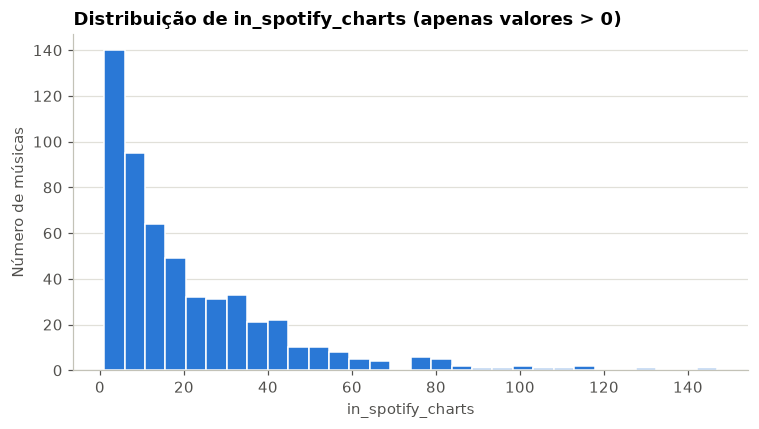

In [ ]:
# Distribuição do charts

fig, ax = plotar_histograma(
    nos_charts["in_spotify_charts"],
    bins=30,
    titulo="Distribuição de in_spotify_charts (apenas valores > 0)",
    rotulo_x="in_spotify_charts",
    caminho="../figures/charts_histograma.png",
)

**Leitura (playlists):** assim como `streams`, a presença em playlists tem assimetria forte à
direita; em escala logarítmica, a distribuição fica aproximadamente simétrica.

**Leitura (charts):** 402 músicas (42,4%) estão fora dos charts (valor 0). Entre as 547 com valor
positivo, a variável se correlaciona positivamente com `streams` (ρ = 0,17) e com playlists
(ρ = 0,24), e cerca de 140 músicas têm valores entre 1 e 5. Conclusão: `in_spotify_charts` é
tratada como **medida de presença nos charts (maior = mais presença)**; o que exatamente é contado
não é documentado (limitação). Os zeros representam o nível mais baixo da escala ("fora dos
charts").

**Observação:** `streams` e `in_spotify_playlists` têm correlação muito forte (ρ = 0,88).

## 3. Comparações por grupo (hipóteses exploratórias 1 a 3)
Compara-se a distribuição de `streams` entre grupos por meio da mediana, dos quartis e de boxplots
(em escala logarítmica, pela forte assimetria). Sem testes de hipótese, as diferenças observadas
descrevem este conjunto de dados; diferenças pequenas diante da variação dentro dos grupos podem
ser fruto do acaso.

In [ ]:
# Coluna só para deixar as colunas e gráficos mais legíveis:

df["streams_mi"] = df["streams"] / 1_000_000

### 3.1 Hipótese 1: colaborações têm mais streams que músicas de um só artista?

,n,mediana,Q1,Q3,média
colaboracao,,,,,
Artista solo,582,333.62,167.42,797.35,568.91
Colaboração,365,236.87,116.14,540.54,428.73


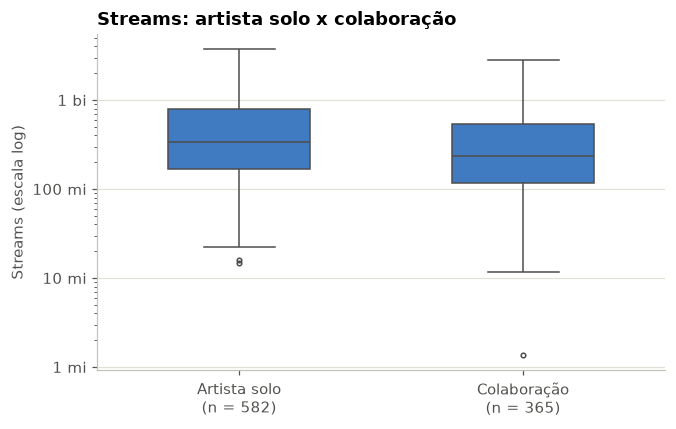

In [ ]:
df["colaboracao"] = np.where(df["artist_count"] >= 2, "Colaboração", "Artista solo")

ordem_h1 = ["Artista solo", "Colaboração"]
display(resumir_por_grupo(df, "colaboracao", "streams_mi").loc[ordem_h1])

fig, ax = plotar_boxplot(
    df, "colaboracao", "streams_mi", ordem=ordem_h1,
    titulo="Streams: artista solo x colaboração",
    rotulo_y="Streams (escala log)", escala_log=True,
)
rotular_eixo_log_milhoes(ax)
fig.savefig("../figures/h1_colaboracao_boxplot.png", bbox_inches="tight")

In [ ]:
periodo = np.where(df["released_year"] >= 2020, "2020 em diante", "Antes de 2020")
pd.crosstab(periodo, df["colaboracao"], normalize="index", rownames=["período"]).round(2)

colaboracao,Artista solo,Colaboração
período,,
2020 em diante,0.56,0.44
Antes de 2020,0.79,0.21


**Leitura:** a hipótese não se confirma neste dataset. No conjunto completo, as músicas de artista
solo têm mediana de streams cerca de 41% maior que as colaborações (334 mi x 237 mi), com grande
sobreposição entre os boxplots. Porém, ao comparar apenas músicas de 2022,
a vantagem cai para cerca de 9% (229 mi x 209 mi), com Q1 e Q3 quase iguais. Ou seja, a maior parte
da diferença observada no conjunto completo está associada ao período de lançamento e não ao formato da música. Porém, associação não implica causa. Isso pode ser explicado pela composição do dataset: entre as músicas lançadas antes de 2020 (que tiveram anos para acumular streams), 79% são de artista solo e só 21% são colaborações; de 2020 em diante, as colaborações chegam a 44%.

### 3.2 Hipótese 2: músicas em tom maior têm mais streams que em tom menor?

,n,mediana,Q1,Q3,média
modo,,,,,
Maior,546,302.61,153.00,686.32,535.92
Menor,401,273.01,127.03,618.99,486.24


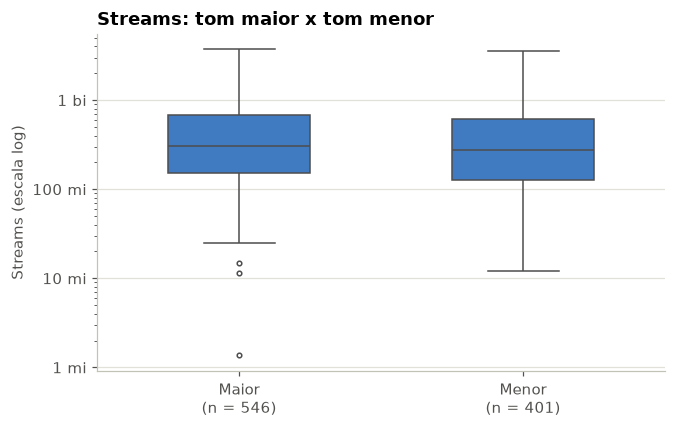

In [ ]:
df["modo"] = df["mode"].map({"Major": "Maior", "Minor": "Menor"})

ordem_h2 = ["Maior", "Menor"]
display(resumir_por_grupo(df, "modo", "streams_mi").loc[ordem_h2])

fig, ax = plotar_boxplot(
    df, "modo", "streams_mi", ordem=ordem_h2,
    titulo="Streams: tom maior x tom menor",
    rotulo_y="Streams (escala log)", escala_log=True,
)
rotular_eixo_log_milhoes(ax)
fig.savefig("../figures/h2_modo_boxplot.png", bbox_inches="tight")

**Leitura:** músicas em tom maior têm mediana ligeiramente superior (303 mi x 273 mi, ~11%), mas as
caixas praticamente coincidem: não há indício de diferença relevante associada ao tom neste
dataset.

### 3.3 Hipótese 3: o trimestre de lançamento está associado a streams?
Usando apenas músicas de 2022, pois 2023 está incompleto no dataset, e restringir a um ano completo
reduz o viés de tempo de exposição.

,n,mediana,Q1,Q3,média
trimestre,,,,,
T1 (jan–mar),91,197.64,112.86,304.37,257.57
T2 (abr–jun),134,236.71,147.40,351.98,317.12
T3 (jul–set),64,243.55,173.45,382.12,331.45
T4 (out–dez),110,200.90,124.88,322.41,251.00


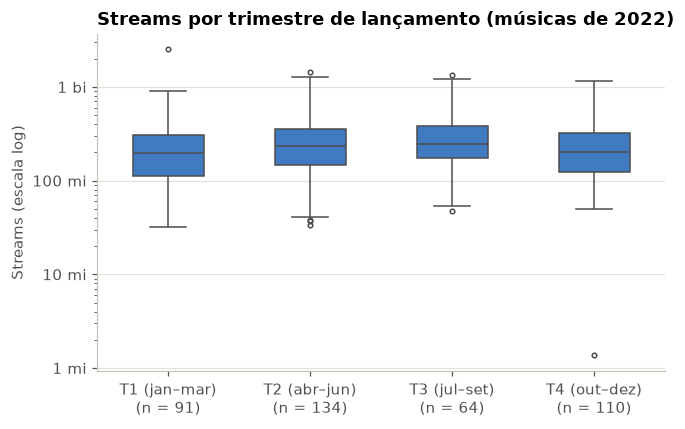

In [ ]:
nomes_trimestres = {1: "T1 (jan–mar)", 2: "T2 (abr–jun)", 3: "T3 (jul–set)", 4: "T4 (out–dez)"}

df_2022 = df[df["released_year"] == 2022].copy()
df_2022["trimestre"] = df_2022["data_lancamento"].dt.quarter.map(nomes_trimestres)

ordem_h3 = list(nomes_trimestres.values())
display(resumir_por_grupo(df_2022, "trimestre", "streams_mi").loc[ordem_h3])

fig, ax = plotar_boxplot(
    df_2022, "trimestre", "streams_mi", ordem=ordem_h3,
    titulo="Streams por trimestre de lançamento (músicas de 2022)",
    rotulo_y="Streams (escala log)", escala_log=True,
)
rotular_eixo_log_milhoes(ax)
fig.savefig("../figures/h3_trimestre_boxplot.png", bbox_inches="tight")

**Leitura:** entre as músicas de 2022, a ordem T3 > T2 > T4 > T1 se repete na mediana, no Q1 e no Q3,
mas as diferenças formam dois blocos: meio do ano (T2 e T3, medianas ~240 mi) e pontas do ano
(T1 e T4, ~200 mi), com diferença de cerca de 20% entre eles e boxplots muito sobrepostos.
O T3 tem o menor grupo (n = 64), o que torna sua mediana menos estável.

In [ ]:
df_2022["colaboracao"] = np.where(df_2022["artist_count"] >= 2, "Colaboração", "Artista solo")
resumir_por_grupo(df_2022, "colaboracao", "streams_mi").loc[ordem_h1]

,n,mediana,Q1,Q3,média
colaboracao,,,,,
Artista solo,240,228.70,137.11,338.84,290.04
Colaboração,159,209.11,128.31,323.40,283.93


In [ ]:
periodo = np.where(df["released_year"] >= 2020, "2020 em diante", "Antes de 2020")
pd.crosstab(periodo, df["colaboracao"], normalize="index").round(2)

colaboracao,Artista solo,Colaboração
row_0,,
2020 em diante,0.56,0.44
Antes de 2020,0.79,0.21


## 4. Correlação entre características de áudio e sucesso (hipótese 4)
Correlação de Spearman (baseada em postos, adequada a variáveis assimétricas e robusta a valores
extremos). Força segundo a convenção: |ρ| < 0,1 desprezível; 0,1–0,3 fraca; 0,3–0,5 moderada;
≥ 0,5 forte. Como nesse projeto não serão feitos teste de hipótese, é importante ressaltar que mesmo correlações fracas podem ser fruto do acaso.

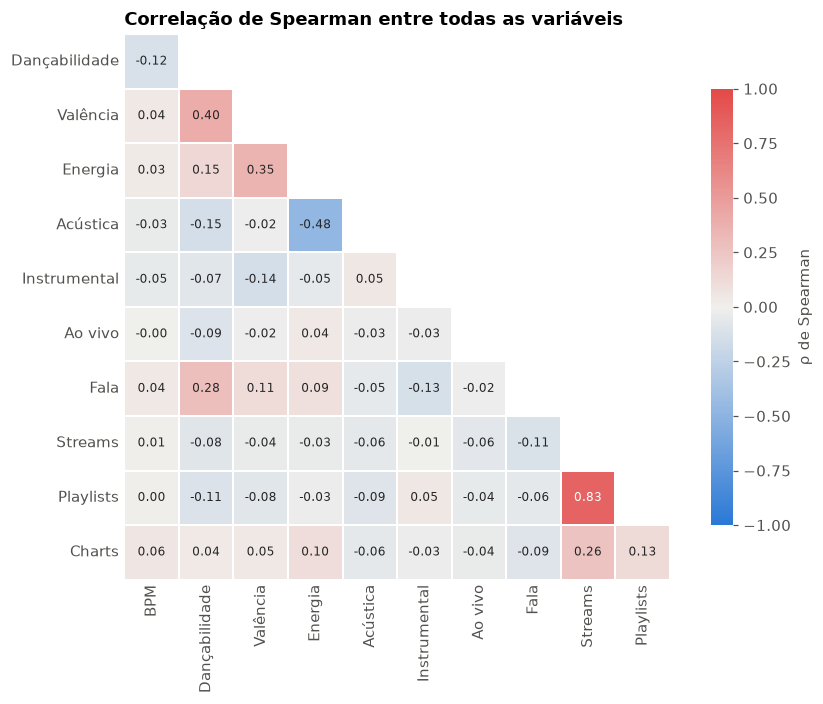

In [ ]:
matriz = df[caracteristicas_audio + variaveis_sucesso].corr(method="spearman")

fig, ax = plotar_heatmap(
    matriz.rename(index=rotulos_pt, columns=rotulos_pt),
    titulo="Correlação de Spearman entre todas as variáveis",
    triangular=True,
    caminho="../figures/correlacao_matriz_completa.png",
)

**Leitura (matriz completa):** as características de áudio se relacionam entre si de forma coerente
com a música (energia × acústica: ρ = −0,48; dançabilidade × valência: ρ = 0,40; valência × energia:
ρ = 0,35), mostrando que é possível captar as relações existententes. Além disso, entre as medidas de sucesso, streams e playlists têm correlação forte (ρ = 0,83), charts se associa de forma mais fraca com streams, mas ainda possui uma associação notável (ρ = 0,26). Verificação de robustez: a correlação de Pearson com log₁₀(streams) produz
valores praticamente idênticos aos de Spearman (diferença máxima de 0,03).

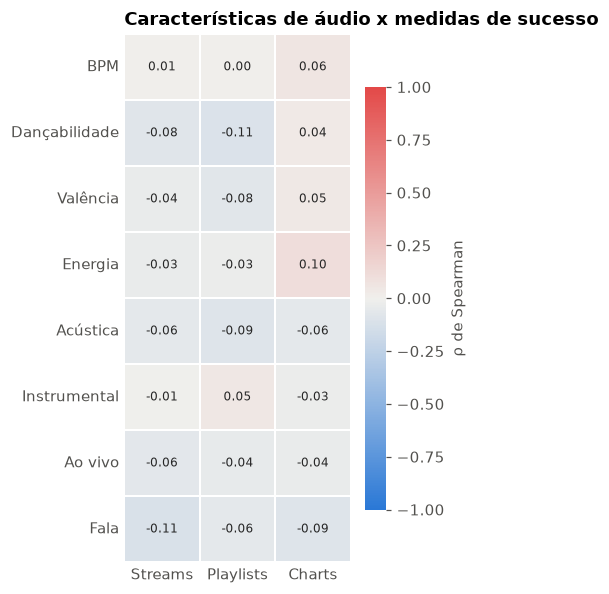

In [ ]:
foco = matriz.loc[caracteristicas_audio, variaveis_sucesso]

fig, ax = plotar_heatmap(
    foco.rename(index=rotulos_pt, columns=rotulos_pt),
    titulo="Características de áudio x medidas de sucesso",
    caminho="../figures/correlacao_audio_sucesso.png",
)

In [ ]:
# Criando uma tabela de classificação da correlação:

foco.map(classificar_correlacao)

,streams,in_spotify_playlists,in_spotify_charts
bpm,desprezível,desprezível,desprezível
danceability,desprezível,fraca negativa,desprezível
valence,desprezível,desprezível,desprezível
energy,desprezível,desprezível,fraca positiva
acousticness,desprezível,desprezível,desprezível
instrumentalness,desprezível,desprezível,desprezível
liveness,desprezível,desprezível,desprezível
speechiness,fraca negativa,desprezível,desprezível


In [ ]:
# Ranking streams:

foco["streams"].sort_values(key=abs, ascending=True)

bpm                 0.01
instrumentalness   -0.01
energy             -0.03
valence            -0.04
acousticness       -0.06
liveness           -0.06
danceability       -0.08
speechiness        -0.11
Name: streams, dtype: float64

**Teste:** Como os resultados de correlação fraca foram surpreendentes, vou testar tentar deixar a distribuição de streams mais simétrica e aplicar pearson. 

In [ ]:
pearson_log = df[caracteristicas_audio].corrwith(np.log10(df["streams"]), method="pearson")

pd.DataFrame({
    "Spearman": foco["streams"],
    "Pearson": pearson_log,
}).round(2)

,Spearman,Pearson
bpm,0.01,0.03
danceability,-0.08,-0.09
valence,-0.04,-0.03
energy,-0.03,-0.03
acousticness,-0.06,-0.03
instrumentalness,-0.01,-0.02
liveness,-0.06,-0.06
speechiness,-0.11,-0.11


In [ ]:
analisar_descritiva(df, caracteristicas_audio)[["mediana", "Q1", "Q3", "mínimo", "máximo"]]

#### Por que as correlações com o sucesso são fracas? (limitação)

Nenhuma característica de áudio apresentou mais do que associação fraca com as três medidas de
sucesso. A correlação de Pearson com logstreams
produz valores praticamente idênticos, e o mesmo cálculo detecta relações esperadas entre as próprias
características (ex.: energia × acústica, ρ = −0,48) e entre as medidas de sucesso
(streams × playlists, ρ = 0,83). A explicação mais provável está na **composição do dataset**:

 **Viés de seleção:** O dataset contém apenas as músicas mais ouvidas
   do Spotify em 2023, e não uma amostra de músicas em geral. Entre esses sucessos, as
   características de áudio variam pouco: metade das músicas tem dançabilidade entre 57 e 78
   (numa escala de 0 a 100), por exemplo. Quando uma variável varia pouco no grupo estudado, sua
   correlação com outras tende a diminuir, mesmo que ela seja relevante numa população mais
   ampla. Assim, os resultados indicam que as características de áudio pouco diferenciam
   **os sucessos entre si**, mas não permitem concluir que elas sejam irrelevantes para
   **chegar ao sucesso**. Responder a essa pergunta exigiria comparar sucessos com músicas
   pouco ouvidas.

### 4.1 Gráficos de dispersão
Comparação visual entre uma correlação forte (streams × playlists) e a mais forte entre as
características de áudio (streams × fala).

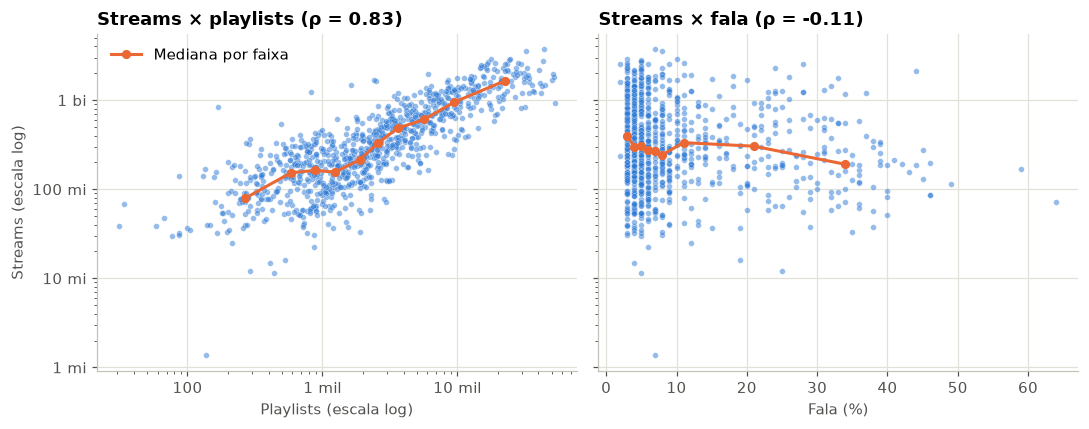

In [ ]:
rho_playlists = df["streams"].corr(df["in_spotify_playlists"], method="spearman")
rho_fala = df["streams"].corr(df["speechiness"], method="spearman")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

plotar_dispersao(ax1, df, "in_spotify_playlists", "streams_mi",
                 rotulo_x="Playlists (escala log)", rotulo_y="Streams (escala log)",
                 log_x=True, log_y=True)
adicionar_linha_medianas(ax1, df, "in_spotify_playlists", "streams_mi")
ax1.set_title(f"Streams × playlists (ρ = {rho_playlists:.2f})", loc="left")
ax1.set_xticks([100, 1_000, 10_000])
ax1.set_xticklabels(["100", "1 mil", "10 mil"])

plotar_dispersao(ax2, df, "speechiness", "streams_mi",
                 rotulo_x="Fala (%)", rotulo_y="", log_y=True)
adicionar_linha_medianas(ax2, df, "speechiness", "streams_mi")
ax2.set_title(f"Streams × fala (ρ = {rho_fala:.2f})", loc="left")

ax1.legend(loc="upper left", frameon=False)
rotular_eixo_log_milhoes(ax1)

fig.tight_layout()
fig.savefig("../figures/dispersao_streams.png", bbox_inches="tight")

**Leitura:** a linha laranja liga as medianas de X e de Y em faixas com aproximadamente o mesmo
número de músicas. Em streams × playlists (ρ = 0,83),
a mediana de streams cresce de forma contínua com o número de playlists. Em streams × fala (ρ = −0,11) a tendência é
levemente decrescente, mas pequena diante da variação dentro de cada faixa. As colunas verticais concentradas no gráfico da fala refletem valores inteiros da coluna `speechiness` concentrados entre aproximadamente 3% e 10% (a maioria das músicas tem pouca fala).